In [2]:
import os, sys, glob
import os.path as op
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
loadFSL()

from fsl.wrappers import fast, flirt
from nilearn import plotting
import matplotlib.pyplot as plt

In [3]:
data_root = op.abspath(op.join("..", "Data1"))
anat_path = op.join(data_root, "T1", "T1w.nii.gz")
print(op.exists(anat_path))

preproc_root = op.join(data_root, "derivatives", "preprocessed_data")
anat_out = op.join(preproc_root, "anat")
mkdir_no_exist(op.join(data_root, "derivatives"))
mkdir_no_exist(preproc_root)
mkdir_no_exist(anat_out)

fig_dir = "figures"
mkdir_no_exist(fig_dir)

mni_brain = op.expandvars("$FSLDIR/data/standard/MNI152_T1_1mm_brain.nii.gz")

True


In [4]:
%gui wx


(ipykernel_launcher.py:2289): dbind-WARNING **: 11:14:08.052: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/203555172/at-spi/bus_100: No such file or directory


In [5]:
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

11:14:11: Debug: Adding duplicate image handler for 'Windows bitmap file'
11:14:11: Debug: Adding duplicate animation handler for '1' type
11:14:11: Debug: Adding duplicate animation handler for '2' type
11:14:11: Debug: Adding duplicate image handler for 'Windows bitmap file'
11:14:11: Debug: Adding duplicate animation handler for '1' type
11:14:11: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:2289): Gtk-CRITICAL **: 11:14:11.772: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:2289): Gtk-CRITICAL **: 11:14:13.973: gtk_window_resize: assertion 'width > 0' failed


In [6]:
## Skull-stripping
betted_brain = op.join(anat_out, "T1w_brain")
os.system('bet {} {} -m -R'.format(anat_path, betted_brain))

0

In [7]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(anat_path)
fsleyesDisplay.load(betted_brain + "_mask")

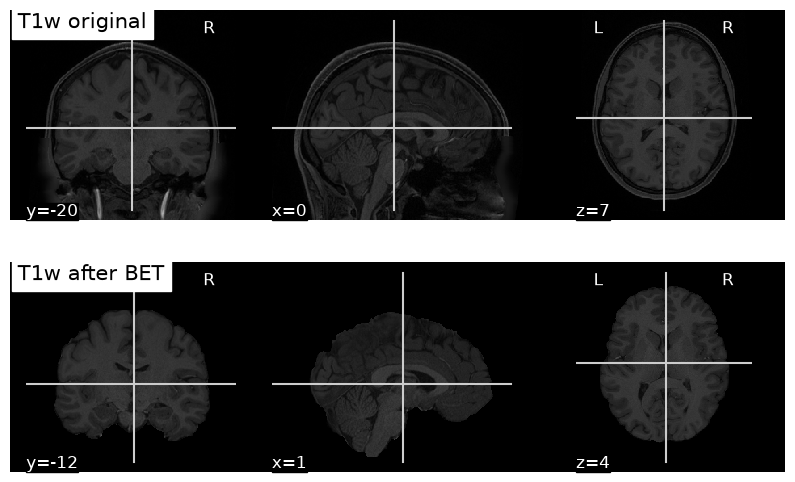

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plotting.plot_anat(anat_path, title="T1w original", axes=axes[0])
plotting.plot_anat(betted_brain + ".nii.gz", title="T1w after BET", axes=axes[1])
plt.savefig(op.join(fig_dir, "1a_skullstrip.png"), dpi=200, bbox_inches="tight")

In [10]:
## Segmentation
segmentation_path = op.join(anat_out, "T1w_fast")
fast(imgs=[betted_brain], out=segmentation_path, n_classes=3)

{}

In [11]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain)
fsleyesDisplay.load(segmentation_path + "_pve_0")
fsleyesDisplay.load(segmentation_path + "_pve_1")
fsleyesDisplay.load(segmentation_path + "_pve_2")
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'

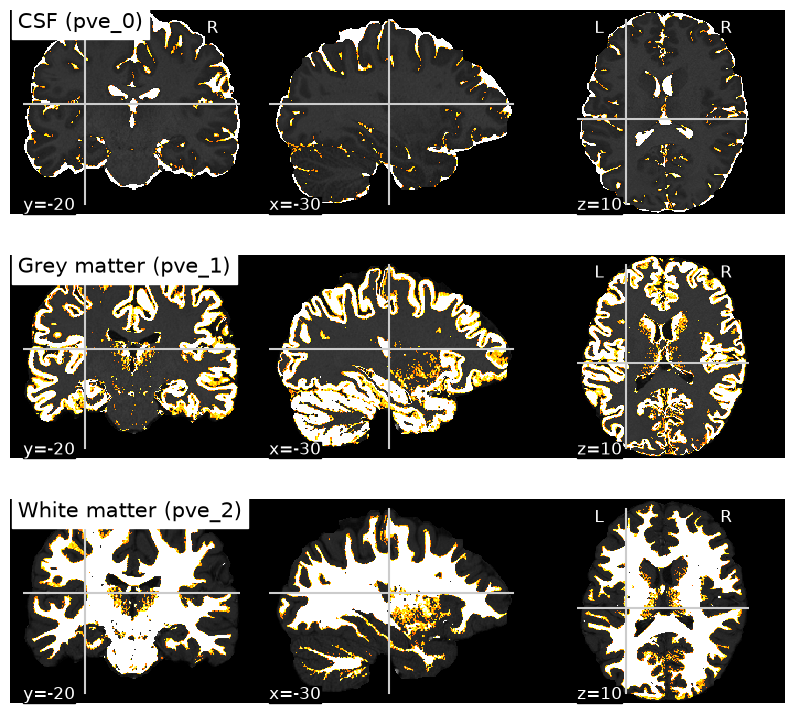

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
names = ["CSF (pve_0)", "Grey matter (pve_1)", "White matter (pve_2)"]
for i, name in enumerate(names):
    plotting.plot_stat_map(f"{segmentation_path}_pve_{i}.nii.gz",
                           bg_img=betted_brain + ".nii.gz",
                           title=name, cmap="hot", threshold=0.5,
                           colorbar=False, cut_coords=(-30, -20, 10),
                           axes=axes[i])
plt.savefig(op.join(fig_dir, "1b_segmentation.png"), dpi=200, bbox_inches="tight")

In [14]:
## Registration (linear)
t1_mni = op.join(anat_out, "T1w_brain_mni")
mat = op.join(anat_out, "T1w2mni.mat")
flirt(betted_brain, mni_brain, out=t1_mni, omat=mat)

{}

In [15]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain)
fsleyesDisplay.load(t1_mni)

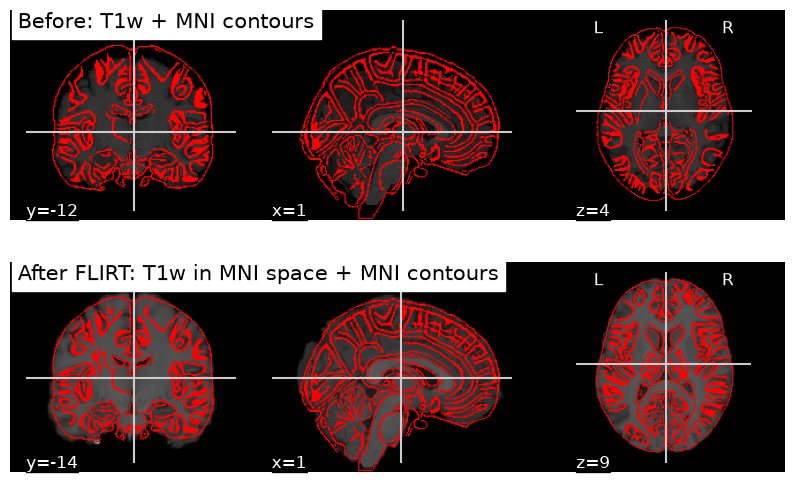

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
d = plotting.plot_anat(betted_brain + ".nii.gz", title="Before: T1w + MNI contours", axes=axes[0])
d.add_edges(mni_brain)
d = plotting.plot_anat(t1_mni + ".nii.gz", title="After FLIRT: T1w in MNI space + MNI contours", axes=axes[1])
d.add_edges(mni_brain)
plt.savefig(op.join(fig_dir, "1c_registration.png"), dpi=200, bbox_inches="tight")

In [17]:
## Registration (non linear)
fsl_anat_out = op.join(anat_out, "fsl_anat")
os.system('fsl_anat -i {} -o {} --clobber --nosubcortseg'.format(anat_path, fsl_anat_out))

Sat Oct 17 11:33:25 UTC 2026
Reorienting to standard orientation
Sat Oct 17 11:33:39 UTC 2026
Automatically cropping the image
Starting Single Image Segmentation
T1-weighted image
Imagesize : 260 x 311 x 221
Pixelsize : 0.7 x 0.7 x 0.7

1 6.40003
2 6.58691
3 6.80277
KMeans Iteration 0
KMeans Iteration 1
KMeans Iteration 2
KMeans Iteration 3
KMeans Iteration 4
KMeans Iteration 5
KMeans Iteration 6
KMeans Iteration 7
KMeans Iteration 8
KMeans Iteration 9
KMeans Iteration 10
KMeans Iteration 11
KMeans Iteration 12
KMeans Iteration 13
KMeans Iteration 14
Tanaka Iteration 0 bias field 10
Tanaka-inner-loop-iteration=0 MRFWeightsTotal=6.34411e+07 beta=0.02
Tanaka-inner-loop-iteration=1 MRFWeightsTotal=6.45342e+07 beta=0.02
Tanaka-inner-loop-iteration=2 MRFWeightsTotal=6.45645e+07 beta=0.02
Tanaka-inner-loop-iteration=3 MRFWeightsTotal=6.45654e+07 beta=0.02
Tanaka-inner-loop-iteration=4 MRFWeightsTotal=6.45655e+07 beta=0.02
 CLASS 1 MEAN 402.525 STDDEV 286.756 CLASS 2 MEAN 699.783 STDDEV 71.62

0

In [19]:
mni_head_2mm = op.expandvars("$FSLDIR/data/standard/MNI152_T1_2mm")

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_head_2mm)
fsleyesDisplay.load(op.join(anat_dir, "T1_to_MNI_lin"))
fsleyesDisplay.load(op.join(anat_dir, "T1_to_MNI_nonlin"))

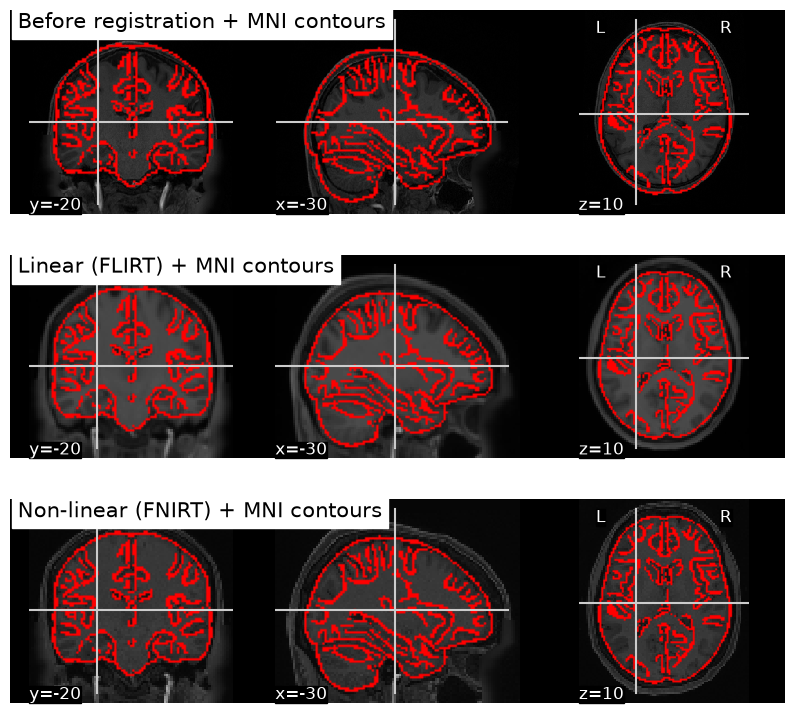

In [21]:
mni_brain_2mm = op.expandvars("$FSLDIR/data/standard/MNI152_T1_2mm_brain.nii.gz")
cuts = (-30, -20, 10)

fig, axes = plt.subplots(3, 1, figsize=(10, 9))
d = plotting.plot_anat(anat_path, title="Before registration + MNI contours",
                       cut_coords=cuts, axes=axes[0])
d.add_edges(mni_brain_2mm)
d = plotting.plot_anat(op.join(anat_dir, "T1_to_MNI_lin.nii.gz"), title="Linear (FLIRT) + MNI contours",
                       cut_coords=cuts, axes=axes[1])
d.add_edges(mni_brain_2mm)
d = plotting.plot_anat(op.join(anat_dir, "T1_to_MNI_nonlin.nii.gz"), title="Non-linear (FNIRT) + MNI contours",
                       cut_coords=cuts, axes=axes[2])
d.add_edges(mni_brain_2mm)
plt.savefig(op.join(fig_dir, "1c_registration.png"), dpi=200, bbox_inches="tight")